# EXPT NO: 7 — TEXT PREPROCESSING AND EMBEDDING GENERATION USING NLP LIBRARIES

**Aim:** To perform text preprocessing using NLTK and generate word embeddings using Gensim Word2Vec to analyze semantic relationships between words.

**Student Roll No(s):24BAD122
NAME:SWATHI

## PART A: DATASET PREPARATION AND TEXT PREPROCESSING

In [1]:
# Student Roll Nos: <ENTER ROLL NUMBERS HERE>
!pip install -q gensim nltk

import nltk, string
for pkg in ["brown", "punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4"]:
    nltk.download(pkg, quiet=True)

from nltk.corpus import brown, stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

# Load the Brown Corpus and select a category
CATEGORY = "news"
raw_sents = brown.sents(categories=CATEGORY)
print("Category:", CATEGORY, "| Number of sentences:", len(raw_sents))

# Examine sample sentences
for i in range(3):
    print(f"Sample {i+1}:", " ".join(raw_sents[i]))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 54.9 MB/s eta 0:00:00
Category: news | Number of sentences: 4623
Sample 1: The Fulton County Grand Jury said Friday an investigation of Atlanta's recent primary election produced `` no evidence '' that any irregularities took place .
Sample 2: The jury further said in term-end presentments that the City Executive Committee , which had over-all charge of the election , `` deserves the praise and thanks of the City of Atlanta '' for the manner in which the election was conducted .
Sample 3: The September-October term jury had been charged by Fulton Superior Court Judge Durwood Pye to investigate reports of possible `` irregularities '' in the hard-fought primary which was won by Mayor-nominate Ivan Allen Jr. .


In [2]:
# Preprocessing: lowercase -> tokenize -> remove punctuation & stop words -> lemmatize
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def preprocess(sentence):
    text = sentence.lower()                                   # lowercase
    tokens = word_tokenize(text)                              # tokenization
    tokens = [t for t in tokens
              if t not in string.punctuation and t.isalpha()] # remove punctuation / symbols
    tokens = [t for t in tokens if t not in stop_words]       # remove stop words
    tokens = [lemmatizer.lemmatize(t) for t in tokens]        # lemmatization
    return tokens

original_sents = [" ".join(s) for s in raw_sents]
processed_sents = [preprocess(s) for s in original_sents]
processed_sents = [s for s in processed_sents if len(s) > 1]   # drop empty / 1-word sentences

# Display original vs preprocessed text
for i in range(3):
    print("Original    :", original_sents[i])
    print("Preprocessed:", processed_sents[i], "\n")
print("Sentences after preprocessing:", len(processed_sents))

Original    : The Fulton County Grand Jury said Friday an investigation of Atlanta's recent primary election produced `` no evidence '' that any irregularities took place .
Preprocessed: ['fulton', 'county', 'grand', 'jury', 'said', 'friday', 'investigation', 'atlanta', 'recent', 'primary', 'election', 'produced', 'evidence', 'irregularity', 'took', 'place'] 

Original    : The jury further said in term-end presentments that the City Executive Committee , which had over-all charge of the election , `` deserves the praise and thanks of the City of Atlanta '' for the manner in which the election was conducted .
Preprocessed: ['jury', 'said', 'presentment', 'city', 'executive', 'committee', 'charge', 'election', 'deserves', 'praise', 'thanks', 'city', 'atlanta', 'manner', 'election', 'conducted'] 

Original    : The September-October term jury had been charged by Fulton Superior Court Judge Durwood Pye to investigate reports of possible `` irregularities '' in the hard-fought primary whic

## PART B: VOCABULARY GENERATION AND WORD FREQUENCY ANALYSIS

Total tokens   : 47604
Vocabulary size: 9885

Ten most frequent words:
  said           406
  year           260
  would          249
  new            241
  state          223
  one            222
  last           177
  two            174
  first          158
  president      155


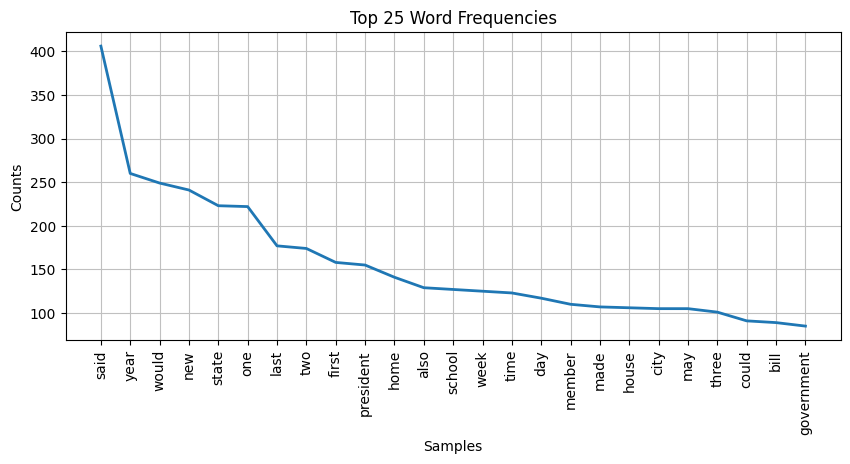


Example Word2Vec input: ['fulton', 'county', 'grand', 'jury', 'said', 'friday', 'investigation', 'atlanta', 'recent', 'primary', 'election', 'produced', 'evidence', 'irregularity', 'took', 'place']


In [3]:
# Student Roll Nos: <ENTER ROLL NUMBERS HERE>
from nltk import FreqDist
import matplotlib.pyplot as plt

all_tokens = [w for sent in processed_sents for w in sent]
vocabulary = sorted(set(all_tokens))
freq_dist = FreqDist(all_tokens)

print("Total tokens   :", len(all_tokens))
print("Vocabulary size:", len(vocabulary))
print("\nTen most frequent words:")
for word, count in freq_dist.most_common(10):
    print(f"  {word:<15}{count}")

# Frequency distribution plot
plt.figure(figsize=(10, 4))
freq_dist.plot(25, title="Top 25 Word Frequencies")
plt.show()

# Tokenized sentences ready for Word2Vec
sentences_for_w2v = processed_sents
print("\nExample Word2Vec input:", sentences_for_w2v[0])

## PART C: WORD EMBEDDING GENERATION USING WORD2VEC

In [4]:
# Student Roll Nos: <ENTER ROLL NUMBERS HERE>
from gensim.models import Word2Vec

model = Word2Vec(
    sentences=sentences_for_w2v,
    vector_size=100,   # embedding dimension
    window=5,          # context window size
    sg=1,              # 1 = Skip-gram (0 = CBOW)
    min_count=2,       # ignore very rare words
    workers=4,
    epochs=30,
    seed=42)

print("Word2Vec vocabulary size:", len(model.wv))

Word2Vec vocabulary size: 5155


In [5]:
# Embedding vector for a selected word
word = "government"
vec = model.wv[word]
print(f"Embedding for '{word}':\n", vec)
print("\nVector dimensions:", vec.shape)

# Five most similar words
print(f"\nTop 5 words similar to '{word}':")
for w, score in model.wv.most_similar(word, topn=5):
    print(f"  {w:<15}{score:.4f}")

Embedding for 'government':
 [ 0.07491435  0.09617554  0.89825785  0.4101893   0.24746217  0.5394128
 -0.13327788  0.23756085  0.37285113 -0.60570925 -0.23996153 -0.09079745
  0.516057    0.5544637  -0.09441075 -0.7054072   0.2780554  -0.36017695
 -0.70099765  0.13904516 -0.06571566  0.52102536 -0.5860139   0.557356
 -0.4091025   0.9909447  -0.36473316 -0.2229824   0.01558015 -0.19952698
 -0.63266474 -0.07957999 -0.54778916 -0.19549322 -0.14137831  0.07135578
  0.58057904  0.22433805 -0.01247924 -0.63915163  0.15509982 -0.7911692
 -0.08273976 -0.6207254   0.4278892   0.00205945  0.7471228   0.20229428
  1.2299783  -0.5198467  -0.14995386  0.520006    0.010224   -0.15320115
  0.29768497  0.20569319 -0.44235465  0.6239776  -0.22099802 -0.28076652
 -0.17588297 -0.07175241 -0.3636188  -0.57971585  0.16658483  0.11307654
 -0.5118829  -0.01115676 -0.4980472  -0.44739527 -0.11378906 -0.01754896
  0.3463506  -0.6667584   0.17780708  0.37066972  0.48962787 -0.33103818
 -0.1950124  -1.3677962   

## PART D: WORD SIMILARITY ANALYSIS AND EXPERIMENT MANAGEMENT

In [6]:
# Student Roll Nos: <ENTER ROLL NUMBERS HERE>
import pandas as pd

# Three word pairs (edit if a word is missing from the vocabulary)
pairs = [("president", "government"), ("city", "state"), ("year", "week")]

rows = []
for a, b in pairs:
    if a in model.wv and b in model.wv:
        rows.append({"Word 1": a, "Word 2": b, "Cosine Similarity": round(float(model.wv.similarity(a, b)), 4)})
    else:
        print(f"Skipped ({a}, {b}) - not in vocabulary")

sim_df = pd.DataFrame(rows).sort_values("Cosine Similarity", ascending=False).reset_index(drop=True)
display(sim_df)

best = sim_df.iloc[0]
print(f"Most similar pair: ({best['Word 1']}, {best['Word 2']}) with similarity {best['Cosine Similarity']}")

,Word 1,Word 2,Cosine Similarity
0,year,week,0.5036
1,president,government,0.1829
2,city,state,0.1437


Most similar pair: (year, week) with similarity 0.5036


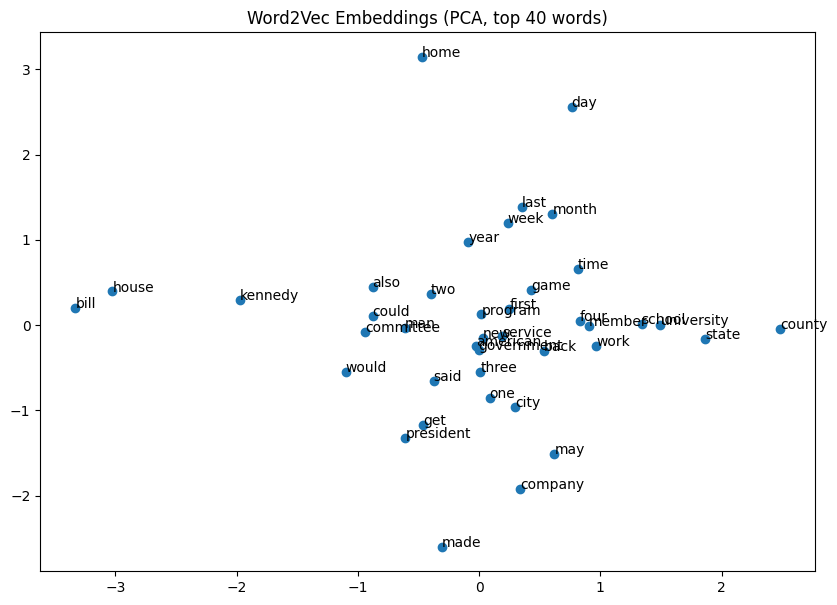

In [7]:
# Optional: 2-D visualization of embeddings (PCA)
from sklearn.decomposition import PCA

words = [w for w, _ in freq_dist.most_common(40) if w in model.wv]
coords = PCA(n_components=2).fit_transform([model.wv[w] for w in words])

plt.figure(figsize=(10, 7))
plt.scatter(coords[:, 0], coords[:, 1])
for w, (x, y) in zip(words, coords):
    plt.annotate(w, (x, y))
plt.title("Word2Vec Embeddings (PCA, top 40 words)")
plt.show()